# Omnifold Exercise #

##### Import relevant libaries #####

In [3]:
import tensorflow as tf
import time

import numpy as np
import matplotlib.pyplot as plt

OmniFold: A Method to Simultaneously Unfold All Observables <br> *Anders Andreassen, Patrick T. Komiske, Eric M. Metodiev, Benjamin Nachman and Jesse Thaler*<br>https://arxiv.org/pdf/1911.09107

We are going to work with a dataset from https://zenodo.org/records/3548091. In particular, we will be looking into three jet-substructure observables of the leading jet, the jet width, the soft-drop mass and the $N_{12}$-subjetiness ratio. The goal is to unfold detector effects and infer $p_\text{data} (x_\text{reco}) \rightarrow p_\text{unfold} (x_\text{part})$ of the 3-dimensional phase space.

Load data

In [4]:
reco_sim = np.load("reco_MC.npy").astype(np.float32)
reco_data = np.load("reco_data.npy").astype(np.float32)
part_sim = np.load("part_MC.npy").astype(np.float32)
part_data = np.load("part_data.npy").astype(np.float32)

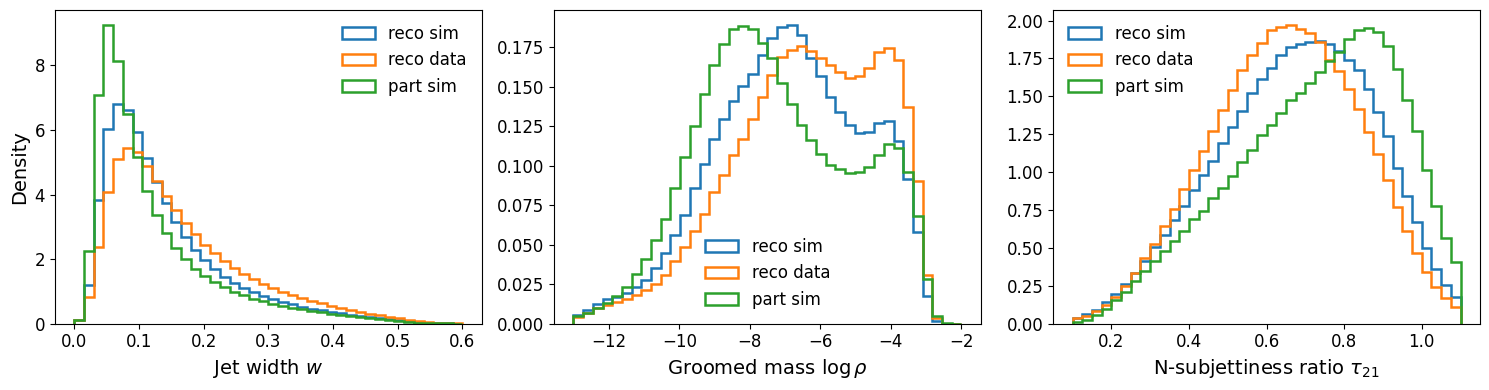

In [5]:
FONTSIZE = 14

n_features = reco_sim.shape[1]

binning = [np.linspace(0, 0.6, 40 + 1),
           np.linspace(-13, -2, 40 + 1),
           np.linspace(0.1, 1.1, 40 + 1)]

names = [r"\text{Jet width } w",
         r"\text{Groomed mass }\log \rho",
         r"\text{N-subjettiness ratio } \tau_{21}"]

fig, axes = plt.subplots(1, n_features, figsize=(5 * n_features, 4), sharey=False)

for i in range(n_features):
    ax = axes[i] if n_features > 1 else axes

    ax.hist(reco_sim[:, i], bins=binning[i], density=True, histtype="step", linewidth=1.8, label="reco sim")
    ax.hist(reco_data[:, i], bins=binning[i], density=True, histtype="step", linewidth=1.8, label="reco data")
    ax.hist(part_sim[:, i], bins=binning[i], density=True, histtype="step", linewidth=1.8, label="part sim")

    ax.set_xlabel(rf"${names[i]}$", fontsize=FONTSIZE)
    if i == 0:
        ax.set_ylabel("Density", fontsize=FONTSIZE)
    ax.tick_params(labelsize=FONTSIZE - 2)
    ax.legend(frameon=False, fontsize=FONTSIZE - 2)

plt.tight_layout()
plt.show()

Build training and test datasets if needed

In [6]:
reco_sim_train, reco_sim_test = reco_sim[:750000], reco_sim[750000:]
reco_data_train, reco_data_test = reco_data[:750000], reco_data[750000:]
part_sim_train, part_sim_test = part_sim[:750000], part_sim[750000:]

We will define some preprocessing functions to apply to the data.

In [7]:
mean = np.array([0.1411, -6.9493, 0.6731], dtype=np.float32)
std = np.array([0.0960, 2.2009, 0.2031], dtype=np.float32)

In [8]:
def preprocess(data, mean, std, reverse=False):
    """
    Standardizes or un-standardizes NumPy arrays.

    Args:
        data (array-like): Input data.
        mean (array-like or float): Mean used for standardization.
        std (array-like or float): Standard deviation used for standardization.
        reverse (bool): If True, reverses the standardization.

    Returns:
        np.ndarray: Processed data array.
    """
    data = np.asarray(data, dtype=np.float32)
    mean = np.asarray(mean, dtype=np.float32)
    std = np.asarray(std, dtype=np.float32)
    if not reverse:
        return (data - mean) / std
    return (data * std) + mean


In [9]:
# Copy and preprocess the data to standardize input features with reco-level MC mean and standard deviation.

reco_sim_proc_train = preprocess(reco_sim_train.copy(), mean, std)
reco_sim_proc_test = preprocess(reco_sim_test.copy(), mean, std)

reco_data_proc_train = preprocess(reco_data_train.copy(), mean, std)

part_sim_proc_train = preprocess(part_sim_train.copy(), mean, std)
part_sim_proc_test = preprocess(part_sim_test.copy(), mean, std)

### Exercise 1 - Building a Classifier in TensorFlow/Keras

In this first exercise, implement a flexible binary classifier using TensorFlow/Keras, which will then serve as a core component in the OmniFold algorithm.

The aim is to build a reusable classifier class or a set of functions. A modular design allows us to train and evaluate the classifier multiple times throughout the unfolding process.


In [10]:
def build_classifier(input_dim=3, hidden_units=[64, 64, 64], activation="relu", learning_rate=1e-3):
    """
    Builds and compiles a simple dense binary classifier.

    Args:
        input_dim (int): Number of input features.
        hidden_units (list): Number of units in each hidden layer.
        activation (str): Activation function for hidden layers.
        learning_rate (float): Learning rate for Adam optimizer.

    Returns:
        tf.keras.Model: Compiled Keras model.
    """
    inputs = tf.keras.Input(shape=(input_dim,))
    x = inputs
    for units in hidden_units:
        x = tf.keras.layers.Dense(units, activation=activation)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


def train_classifier(model, X0, X1, weights0=None, weights1=None,
                     epochs=10, batch_size=10000, verbose=0):
    """
    Trains the classifier to distinguish class 0 (X0) from class 1 (X1).
    Optionally accepts per-sample weights for each class.

    Args:
        model: Compiled Keras model.
        X0 (np.ndarray): Samples labelled 0.
        X1 (np.ndarray): Samples labelled 1.
        weights0 (np.ndarray or None): Per-sample weights for X0.
        weights1 (np.ndarray or None): Per-sample weights for X1.
        epochs (int): Training epochs.
        batch_size (int): Mini-batch size.
        verbose (int): Keras verbosity.

    Returns:
        tf.keras.callbacks.History
    """
    n0, n1 = len(X0), len(X1)
    X = np.concatenate([X0, X1], axis=0)
    y = np.concatenate([np.zeros(n0), np.ones(n1)], axis=0).astype(np.float32)

    if weights0 is None:
        weights0 = np.ones(n0, dtype=np.float32)
    if weights1 is None:
        weights1 = np.ones(n1, dtype=np.float32)

    # Normalise so total weight of each class is equal
    weights0 = weights0 / weights0.sum() * n0
    weights1 = weights1 / weights1.sum() * n1
    sample_weights = np.concatenate([weights0, weights1])

    history = model.fit(
        X, y,
        sample_weight=sample_weights,
        epochs=epochs,
        batch_size=batch_size,
        verbose=verbose,
        shuffle=True,
    )
    return history


def get_weights(model, X):
    """
    Converts classifier outputs to likelihood ratio weights w = f/(1-f).

    Args:
        model: Trained Keras model.
        X (np.ndarray): Input samples.

    Returns:
        np.ndarray: Likelihood-ratio weights, clipped to [1e-6, 1e6].
    """
    f = model.predict(X, batch_size=10000, verbose=0).flatten()
    f = np.clip(f, 1e-6, 1 - 1e-6)
    return f / (1.0 - f)


### Exercise 2 - Single Iteration Omnifold

To get a better understanding of omnifold we will start by doing the first iteration explicitly. For one iteration implement the following steps:

1. Train a classifier between $p_{\text{sim}}(x_{\text{reco}})$ and $p_{\text{data}}(x_{\text{reco}})$

In [ ]:
# Step 1 – train a classifier between reco-level sim and reco-level data
print("Step 1: Training reco-level classifier (sim vs data)...")
t0 = time.time()

clf_reco = build_classifier(input_dim=3, hidden_units=[64, 64, 64])
train_classifier(clf_reco,
                 X0=reco_sim_proc_train,   # class 0: sim
                 X1=reco_data_proc_train,  # class 1: data
                 epochs=20, batch_size=10000, verbose=1)

print(f"  Done in {time.time()-t0:.1f}s")

# accuracy at 55% is good in reality because I want to get the two distr as close as possible and they are already close!
# when applimg the weighs I expect to get closer and closer to 0.5


Step 1: Training reco-level classifier (sim vs data)...
Epoch 1/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.5588 - loss: 0.6832
Epoch 2/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.5598 - loss: 0.6827
Epoch 3/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5601 - loss: 0.6826
Epoch 4/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5600 - loss: 0.6825
Epoch 5/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5601 - loss: 0.6825
Epoch 6/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5602 - loss: 0.6825
Epoch 7/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5603 - loss: 0.6825
Epoch 8/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5601 - loss: 0.6824
Epoch 9/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5603 - loss: 0.6824
Epoch 10/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5604 - loss: 0.6824
Epoch 11/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5603 - loss: 

2. Evaluate $w_\theta(x_\text{reco})$ with $x_\text{reco} \sim p_{\text{sim}}(x_{\text{reco}})$

In [12]:
# Step 2 – evaluate w_theta(x_reco) on the full reco-level sim test set
w_reco = get_weights(clf_reco, reco_sim_proc_test)
print(f"w_reco  mean={w_reco.mean():.4f}  std={w_reco.std():.4f}  "
      f"min={w_reco.min():.4f}  max={w_reco.max():.4f}")


w_reco  mean=1.0148  std=0.3010  min=0.2380  max=2.6568


3. Plot $p_\text{sim}(x_\text{reco})$, $p_{\text{data}}(x_{\text{reco}})$ and $w_\theta(x_\text{reco})p_\text{sim}(x_\text{reco})$

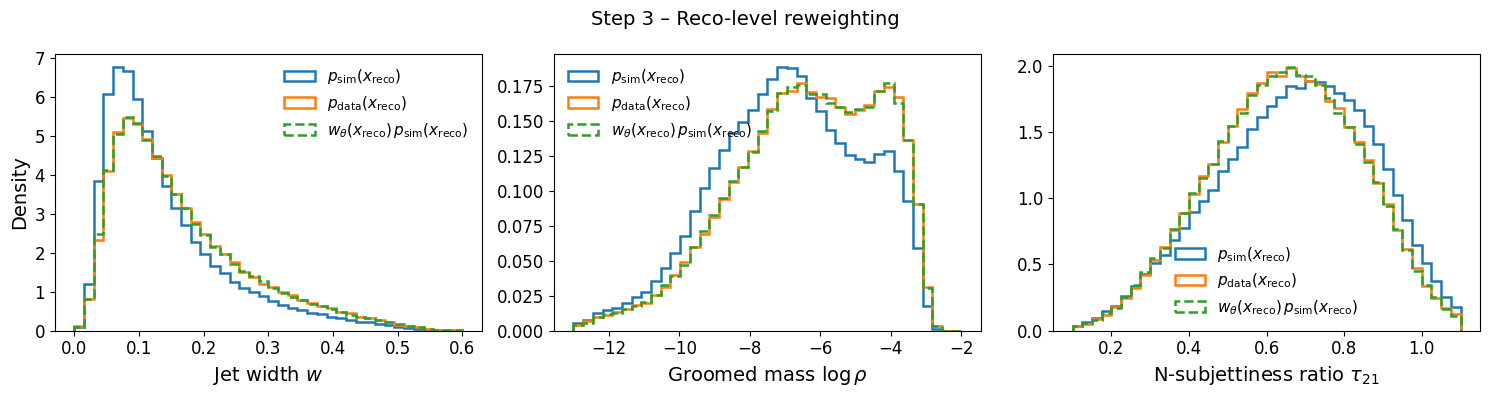

In [13]:
# Step 3 – plot reco-level distributions
def plot_distributions(ax, bins, sim, data, weighted_sim, w_label, names_i):
    ax.hist(sim,  bins=bins, density=True, histtype="step", lw=1.8, label=r"$p_\mathrm{sim}(x_\mathrm{reco})$")
    ax.hist(data, bins=bins, density=True, histtype="step", lw=1.8, label=r"$p_\mathrm{data}(x_\mathrm{reco})$")
    ax.hist(sim,  bins=bins, density=True, histtype="step", lw=1.8, weights=weighted_sim,
            label=w_label, linestyle="--")
    ax.set_xlabel(rf"${names_i}$", fontsize=FONTSIZE)
    ax.legend(frameon=False, fontsize=FONTSIZE - 3)
    ax.tick_params(labelsize=FONTSIZE - 2)

fig, axes = plt.subplots(1, n_features, figsize=(5 * n_features, 4))
for i in range(n_features):
    plot_distributions(
        axes[i], binning[i],
        sim=reco_sim_test[:, i],
        data=reco_data_test[:, i],
        weighted_sim=w_reco,
        w_label=r"$w_\theta(x_\mathrm{reco})\,p_\mathrm{sim}(x_\mathrm{reco})$",
        names_i=names[i],
    )
    if i == 0:
        axes[i].set_ylabel("Density", fontsize=FONTSIZE)

plt.suptitle("Step 3 – Reco-level reweighting", fontsize=FONTSIZE)
plt.tight_layout()
plt.show()


4. Pull the reco-level event to particle-level $w_\theta(x_\text{reco}) \rightarrow w_\theta(x_\text{part})$ using the pairing in simulation
   
5. Plot $p_\text{sim}(x_\text{part})$, $p_{\text{data}}(x_{\text{part}})$ and $w_\theta(x_\text{part})p_\text{sim}(x_\text{part})$

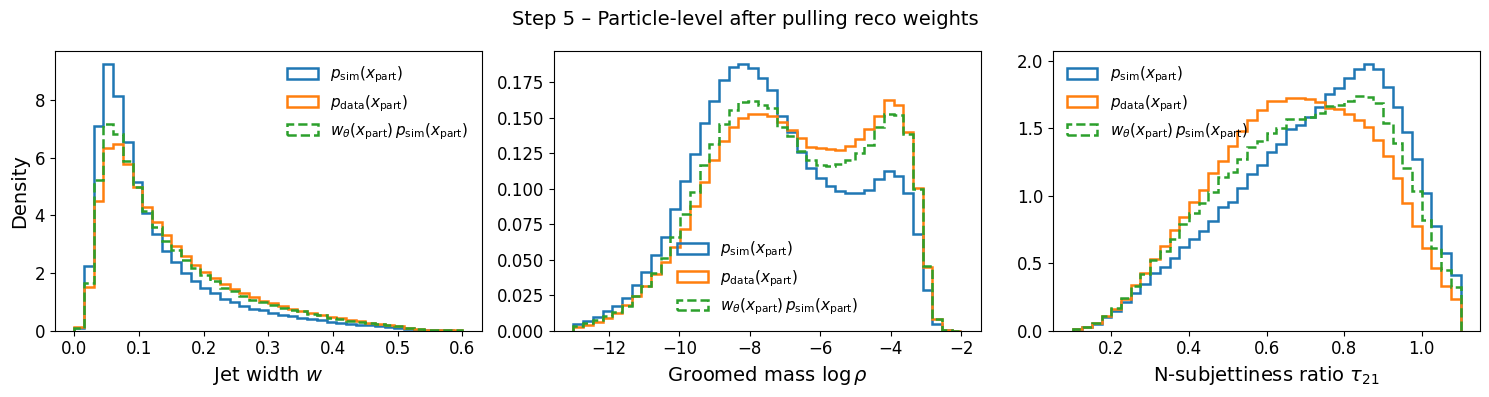

In [14]:
# Step 4 – pull reco weights to particle level using sim pairing
# (same event index in sim: reco_sim_test[i] <-> part_sim_test[i])
w_part_from_reco = w_reco.copy()   # weight i at reco level -> same weight i at particle level

# Step 5 – plot particle-level distributions after pulling
fig, axes = plt.subplots(1, n_features, figsize=(5 * n_features, 4))
for i in range(n_features):
    ax = axes[i]
    ax.hist(part_sim_test[:, i], bins=binning[i], density=True, histtype="step", lw=1.8,
            label=r"$p_\mathrm{sim}(x_\mathrm{part})$")
    ax.hist(part_data[:, i],     bins=binning[i], density=True, histtype="step", lw=1.8,
            label=r"$p_\mathrm{data}(x_\mathrm{part})$")
    ax.hist(part_sim_test[:, i], bins=binning[i], density=True, histtype="step", lw=1.8,
            weights=w_part_from_reco,
            label=r"$w_\theta(x_\mathrm{part})\,p_\mathrm{sim}(x_\mathrm{part})$",
            linestyle="--")
    ax.set_xlabel(rf"${names[i]}$", fontsize=FONTSIZE)
    if i == 0:
        ax.set_ylabel("Density", fontsize=FONTSIZE)
    ax.legend(frameon=False, fontsize=FONTSIZE - 3)
    ax.tick_params(labelsize=FONTSIZE - 2)

plt.suptitle("Step 5 – Particle-level after pulling reco weights", fontsize=FONTSIZE)
plt.tight_layout()
plt.show()


##### What do you observe?

The reweighted sim distribution $w_\\theta(x_\\mathrm{part})\\,p_\\mathrm{sim}(x_\\mathrm{part})$ already tracks $p_\\mathrm{data}(x_\\mathrm{part})$ reasonably well at particle level, even though the classifier was trained at reco level.  However, since detector effects mix information across bins, the match is imperfect — Step 2 (the particle-level classifier) is needed to refine it.

6. Train a classifier between $p_{\text{sim}}(x_{\text{part}})$ and $w_\theta (x_\text{part}) p_{\text{sim}}(x_{\text{part}})$

In [ ]:
# Step 6 – train a classifier between unweighted sim and pulled-back-weighted sim at particle level
print("Step 6: Training particle-level classifier...")
t0 = time.time()

clf_part = build_classifier(input_dim=3, hidden_units=[64, 64, 64])
train_classifier(
    clf_part,
    X0=part_sim_proc_test,          # class 0: unweighted sim (denominator)
    X1=part_sim_proc_test,          # class 1: w-weighted sim (numerator)
    weights0=None,
    weights1=w_part_from_reco,      # pulled-back reco weights
    epochs=20, batch_size=10000, verbose=1,
)
print(f"  Done in {time.time()-t0:.1f}s")


Step 6: Training particle-level classifier...
Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.4995 - loss: 0.6870
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5000 - loss: 0.6861
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5000 - loss: 0.6861
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4998 - loss: 0.6861
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4996 - loss: 0.6861
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4998 - loss: 0.6861
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5000 - loss: 0.6861
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5001 - loss: 0.6861
Epoch 9/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5000 - loss: 0.6860
Epoch 10/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4998 - loss: 0.6861
Epoch 11/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5000 - loss: 0.6861
Epoch 12/20
50/50 ━━━━━━━━

7. Evaluate $\nu_\phi (x_\text{part})$ with $x_\text{part} \sim p_\text{sim}(x_\text{part})$

In [16]:
# Step 7 – evaluate nu_phi(x_part)
nu_part = get_weights(clf_part, part_sim_proc_test)
print(f"nu_part  mean={nu_part.mean():.4f}  std={nu_part.std():.4f}  "
      f"min={nu_part.min():.4f}  max={nu_part.max():.4f}")


nu_part  mean=1.0034  std=0.2575  min=0.5595  max=2.5509


8. Plot $p_\text{sim}(x_\text{part})$, $p_{\text{data}}(x_{\text{part}})$ and $\nu_\phi(x_\text{part})p_\text{sim}(x_\text{part})$

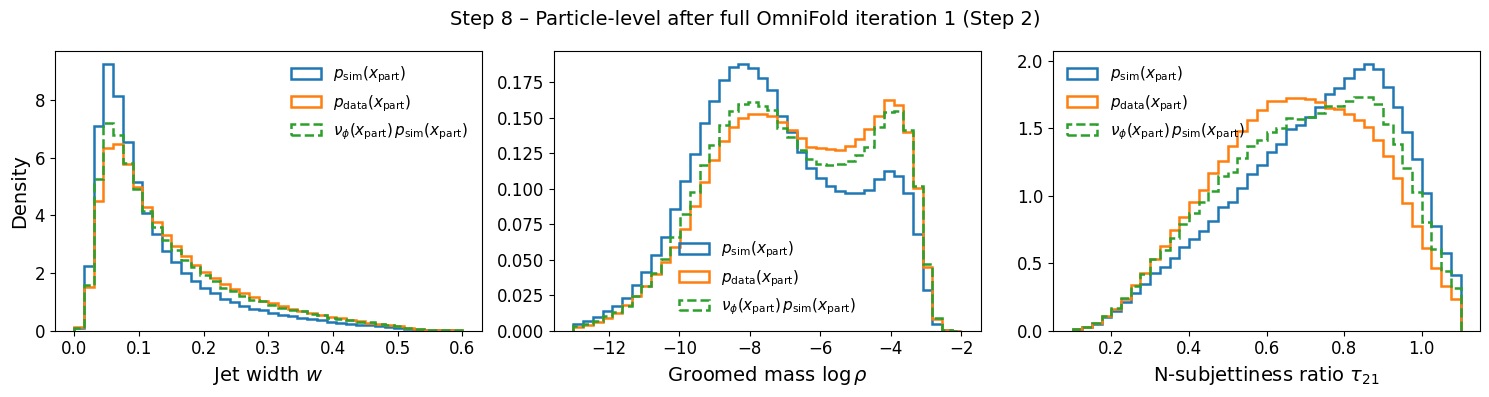

In [17]:
# Step 8 – plot particle-level distributions with nu_phi weights
fig, axes = plt.subplots(1, n_features, figsize=(5 * n_features, 4))
for i in range(n_features):
    ax = axes[i]
    ax.hist(part_sim_test[:, i], bins=binning[i], density=True, histtype="step", lw=1.8,
            label=r"$p_\mathrm{sim}(x_\mathrm{part})$")
    ax.hist(part_data[:, i],     bins=binning[i], density=True, histtype="step", lw=1.8,
            label=r"$p_\mathrm{data}(x_\mathrm{part})$")
    ax.hist(part_sim_test[:, i], bins=binning[i], density=True, histtype="step", lw=1.8,
            weights=nu_part,
            label=r"$\nu_\phi(x_\mathrm{part})\,p_\mathrm{sim}(x_\mathrm{part})$",
            linestyle="--")
    ax.set_xlabel(rf"${names[i]}$", fontsize=FONTSIZE)
    if i == 0:
        ax.set_ylabel("Density", fontsize=FONTSIZE)
    ax.legend(frameon=False, fontsize=FONTSIZE - 3)
    ax.tick_params(labelsize=FONTSIZE - 2)

plt.suptitle("Step 8 – Particle-level after full OmniFold iteration 1 (Step 2)", fontsize=FONTSIZE)
plt.tight_layout()
plt.show()


9. Push the particle-level event to reco-level $\nu_\phi(x_\text{part}) \rightarrow \nu_\phi(x_\text{reco})$ using the pairing in simulation

10. Plot $p_\text{sim}(x_\text{reco})$, $p_{\text{data}}(x_{\text{reco}})$ and $\nu_\phi(x_\text{reco})p_\text{sim}(x_\text{reco})$

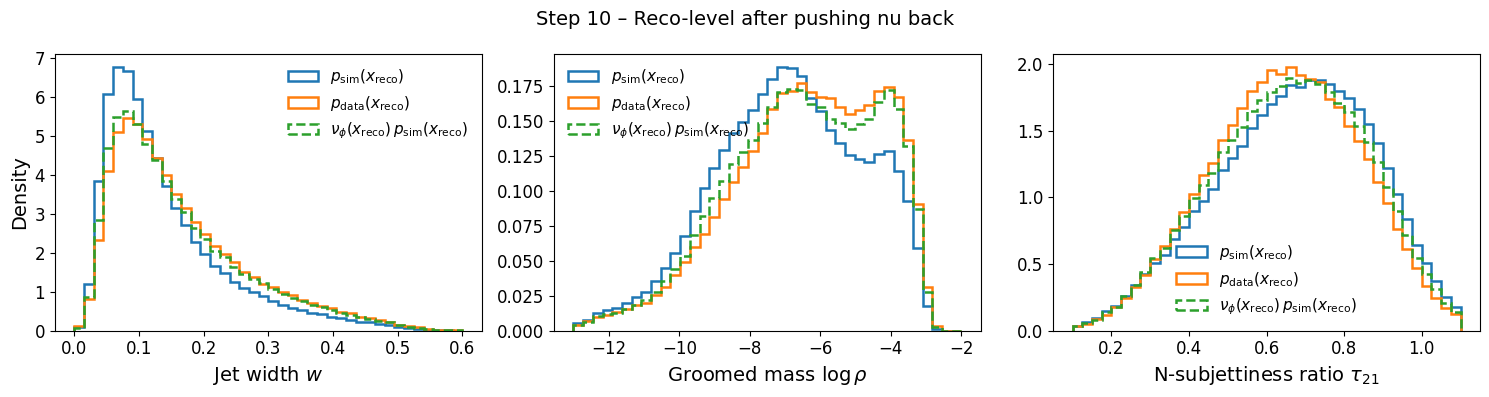

In [18]:
# Step 9 – push particle-level nu weights back to reco level
nu_reco_from_part = nu_part.copy()   # same event-index pairing

# Step 10 – plot reco-level distributions with nu_phi weights
fig, axes = plt.subplots(1, n_features, figsize=(5 * n_features, 4))
for i in range(n_features):
    ax = axes[i]
    ax.hist(reco_sim_test[:, i], bins=binning[i], density=True, histtype="step", lw=1.8,
            label=r"$p_\mathrm{sim}(x_\mathrm{reco})$")
    ax.hist(reco_data_test[:, i], bins=binning[i], density=True, histtype="step", lw=1.8,
            label=r"$p_\mathrm{data}(x_\mathrm{reco})$")
    ax.hist(reco_sim_test[:, i], bins=binning[i], density=True, histtype="step", lw=1.8,
            weights=nu_reco_from_part,
            label=r"$\nu_\phi(x_\mathrm{reco})\,p_\mathrm{sim}(x_\mathrm{reco})$",
            linestyle="--")
    ax.set_xlabel(rf"${names[i]}$", fontsize=FONTSIZE)
    if i == 0:
        ax.set_ylabel("Density", fontsize=FONTSIZE)
    ax.legend(frameon=False, fontsize=FONTSIZE - 3)
    ax.tick_params(labelsize=FONTSIZE - 2)

plt.suptitle("Step 10 – Reco-level after pushing nu back", fontsize=FONTSIZE)
plt.tight_layout()
plt.show()


##### What do you observe?

After the second classifier step (Step 2), $\\nu_\\phi(x_\\mathrm{part})\\,p_\\mathrm{sim}(x_\\mathrm{part})$ matches $p_\\mathrm{data}(x_\\mathrm{part})$ more closely than the result from Step 1 alone.  When pushed back to reco level, $\\nu_\\phi(x_\\mathrm{reco})\\,p_\\mathrm{sim}(x_\\mathrm{reco})$ also reproduces $p_\\mathrm{data}(x_\\mathrm{reco})$ well, confirming that one full OmniFold iteration (Steps 1+2) already captures most of the detector correction.

### Exercise 3 - Iterative Omnifold

Now that we have walked through a single iteration of OmniFold step-by-step, it's time to automate the full iterative unfolding procedure.
Add all indivual steps to an iterative loop.


  OmniFold iteration 1 / 3
  Step 1: reco-level classifier ...
  Step 2: particle-level classifier ...
  nu_phi: mean=0.9772  std=0.2372

  OmniFold iteration 2 / 3
  Step 1: reco-level classifier ...
  Step 2: particle-level classifier ...
  nu_phi: mean=0.9875  std=0.4682

  OmniFold iteration 3 / 3
  Step 1: reco-level classifier ...
  Step 2: particle-level classifier ...
  nu_phi: mean=1.0299  std=0.8153


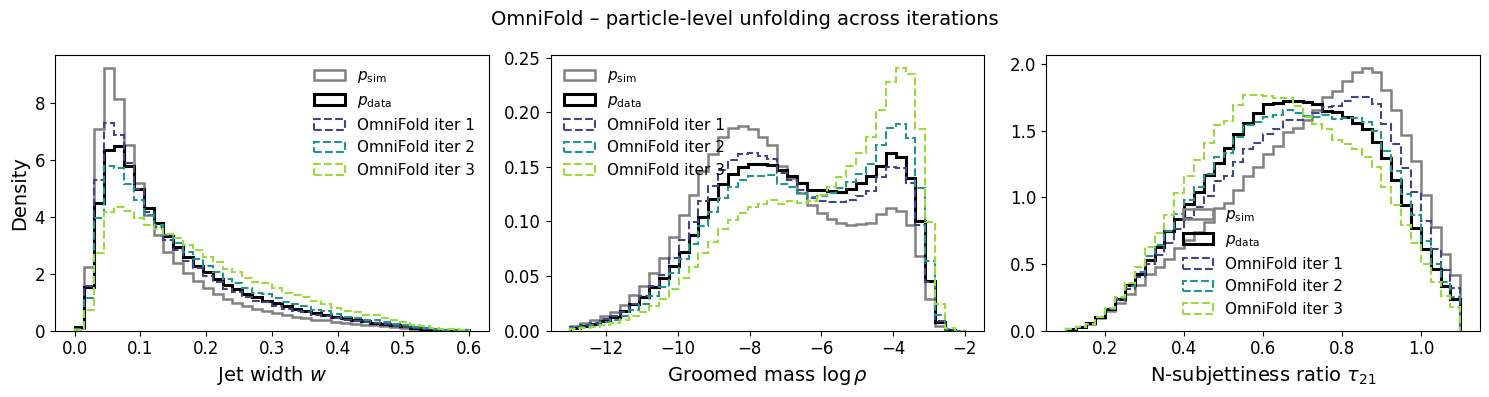

In [19]:
iterations = 3

# Initialise cumulative weights (start from uniform = 1)
weights_step2 = np.ones(len(part_sim_test), dtype=np.float32)

part_sim_proc_test = preprocess(part_sim_test.copy(), mean, std)

all_nu_part = []   # store per-iteration particle weights for final comparison

for it in range(iterations):
    print(f"\n{'='*50}")
    print(f"  OmniFold iteration {it + 1} / {iterations}")
    print(f"{'='*50}")

    # ------------------------------------------------------------------ #
    # STEP 1 – reco-level classifier: sim (weighted by previous step-2   #
    #          weights pushed to reco) vs data                            #
    # ------------------------------------------------------------------ #
    print("  Step 1: reco-level classifier ...")
    clf_step1 = build_classifier(input_dim=3, hidden_units=[64, 64, 64])
    train_classifier(
        clf_step1,
        X0=reco_sim_proc_train,
        X1=reco_data_proc_train,
        weights0=None,            # reco-level weights for sim come from Step 2
        weights1=None,
        epochs=15, batch_size=10000, verbose=0,
    )

    # Evaluate w_theta on TEST set
    w_theta = get_weights(clf_step1, reco_sim_proc_test)

    # Pull back to particle level via event pairing (same index)
    w_theta_part = w_theta * weights_step2   # combine with previous iteration Step-2 weights

    # ------------------------------------------------------------------ #
    # STEP 2 – particle-level classifier: unweighted sim vs               #
    #          w_theta-weighted sim                                        #
    # ------------------------------------------------------------------ #
    print("  Step 2: particle-level classifier ...")
    clf_step2 = build_classifier(input_dim=3, hidden_units=[64, 64, 64])
    train_classifier(
        clf_step2,
        X0=part_sim_proc_test,
        X1=part_sim_proc_test,
        weights0=None,
        weights1=w_theta_part,
        epochs=15, batch_size=10000, verbose=0,
    )

    # Evaluate nu_phi on TEST set
    nu_phi = get_weights(clf_step2, part_sim_proc_test)
    weights_step2 = nu_phi   # update cumulative weights for next iteration

    all_nu_part.append(nu_phi.copy())
    print(f"  nu_phi: mean={nu_phi.mean():.4f}  std={nu_phi.std():.4f}")

# ------------------------------------------------------------------ #
# Final plot – compare particle-level unfolding across iterations    #
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(1, n_features, figsize=(5 * n_features, 4))

colors = plt.cm.viridis(np.linspace(0.2, 0.85, iterations))

for i in range(n_features):
    ax = axes[i]
    ax.hist(part_sim_test[:, i], bins=binning[i], density=True,
            histtype="step", lw=1.8, color="gray", label=r"$p_\mathrm{sim}$")
    ax.hist(part_data[:, i], bins=binning[i], density=True,
            histtype="step", lw=2.2, color="black", label=r"$p_\mathrm{data}$")

    for k, w in enumerate(all_nu_part):
        ax.hist(part_sim_test[:, i], bins=binning[i], density=True,
                histtype="step", lw=1.5, weights=w, color=colors[k],
                linestyle="--", label=f"OmniFold iter {k+1}")

    ax.set_xlabel(rf"${names[i]}$", fontsize=FONTSIZE)
    if i == 0:
        ax.set_ylabel("Density", fontsize=FONTSIZE)
    ax.legend(frameon=False, fontsize=FONTSIZE - 3)
    ax.tick_params(labelsize=FONTSIZE - 2)

plt.suptitle("OmniFold – particle-level unfolding across iterations", fontsize=FONTSIZE)
plt.tight_layout()
plt.show()
